# Word Embeddings

## Notebook for Assignment 2 of the "Text as Data" Course

**Assignment: Word Embeddings and Vector Space Arithmetic**

### Purpose
The purpose of this assignment is to familiarize you with word embeddings and demonstrate how they can represent words in a vector space. You will gain experience performing arithmetic operations on word vectors and explore how these operations capture semantic relationships between words.

Word embeddings are powerful tools in Natural Language Processing (NLP) that map words to high-dimensional vectors based on their contexts within a corpus. These vectors encapsulate semantic meanings and relationships, allowing for mathematical operations that reflect linguistic analogies and similarities.

In this assignment, you will:

1. **Understanding Word Embeddings**  
   - Learn how word embeddings represent semantic meaning.

2. **Vector Arithmetic with Word Embeddings**  
   - Use vector operations to explore word relationships (e.g., _king_ - _man_ + _woman_ ≈ _queen_).

3. **Identifying Latent Topics in Text**  
   - Apply word embeddings to uncover underlying topics in a corpus.

4. **Reflections on Word Embeddings in Campaign Language**  
   - Analyze how word embeddings can enhance a presidential campaign’s language strategy.

**Note:** The code in this notebook is not designed to automatically complete all the assignments. You may need to rearrange and supplement the code to arrive at solutions. Additionally, keep in mind that you are not obligated to use the provided code. You are welcome to write your own code or approach the exercises in a more reflective and analytical manner.

In [36]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Natural Language Processing libraries
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Other basic libraries
import string
import os
from scipy import spatial

# For stemming or lemmatization (optional)
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer

# Import necessary libraries
import gensim
from gensim.models import Word2Vec
import gensim.downloader as api

# Import ml libraries
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Download NLTK data files (only need to run once)
#nltk.download('punkt')
#nltk.download('stopwords')
#nltk.download('wordnet')

In [37]:
# Load the dataset (adjust the file path as needed)

# Define the path to your speech files
speech_directory = 'sotu/'  # Replace with your actual path

# Get a list of all .txt files in the directory
speech_files = [f for f in os.listdir(speech_directory) if f.endswith('.txt')]

# Initialize lists to store data
presidents = []
years = []
texts = []

# Loop through each file and extract data
for filename in speech_files:
    # Extract president and year from the filename
    name_year = filename.replace('.txt', '')
    try:
        president, year = name_year.rsplit('_', 1)
    except ValueError:
        # Handle files that do not follow the expected naming convention
        print(f"Filename '{filename}' does not match the expected format.")
        continue
    
    # Read the text content of the file
    with open(os.path.join(speech_directory, filename), 'r', encoding='utf-8') as file:
        text = file.read()
    
    # Append the data to the lists
    presidents.append(president)
    years.append(int(year))
    texts.append(text)

# Create a DataFrame from the lists
data = pd.DataFrame({
    'president': presidents,
    'year': years,
    'text': texts
})

# Preview the DataFrame
print(data.head())


   president  year                                               text
0     Reagan  1982  Mr. Speaker, Mr. President, distinguished Memb...
1  Roosevelt  1902  To the Senate and House of Representatives:\n\...
2     Wilson  1914  GENTLEMEN OF THE CONGRESS:\n\nThe session upon...
3       Taft  1911  PART I\n\nThis message is the first of several...
4    Madison  1814  Fellow-Citizens of the Senate and House of Rep...


In [38]:
# Data Preprocessing
# Initialize stop words and punctuation
stop_words = set(stopwords.words('english'))
punctuations = set(string.punctuation)

# Initialize stemmer or lemmatizer (choose one)
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Define a preprocessing function
def preprocess_text(text, use_stemming=False, use_lemmatization=False):
    # Convert text to lowercase
    text = text.lower()
    # Tokenize the text into words
    tokens = word_tokenize(text)
    # Remove punctuation from each token and remove tokens that are punctuation
    tokens = [word for word in tokens if word not in punctuations]
    # Remove stop words
    tokens = [word for word in tokens if word not in stop_words]
    # Optionally perform stemming or lemmatization
    if use_stemming:
        tokens = [stemmer.stem(word) for word in tokens]
    elif use_lemmatization:
        tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return tokens

# Apply the preprocessing function to the 'text' column
data['tokens'] = data['text'].apply(lambda x: preprocess_text(x, use_stemming=False, use_lemmatization=True))

# Display the first few rows with the new 'tokens' column
data[['text', 'tokens']].head()

,text,tokens
0,"Mr. Speaker, Mr. President, distinguished Memb...","[mr., speaker, mr., president, distinguished, ..."
1,To the Senate and House of Representatives:\n\...,"[senate, house, representative, still, continu..."
2,GENTLEMEN OF THE CONGRESS:\n\nThe session upon...,"[gentleman, congress, session, upon, entering,..."
3,PART I\n\nThis message is the first of several...,"[part, message, first, several, shall, send, c..."
4,Fellow-Citizens of the Senate and House of Rep...,"[fellow-citizens, senate, house, representativ..."


In [39]:
# Example: View the tokens for the first speech
print("Original Text:\n")
print(data['text'].iloc[0][:500])  # Show first 500 characters
print("\nPreprocessed Tokens:\n")
print(data['tokens'].iloc[0][:50])  # Show first 50 tokens

Original Text:

Mr. Speaker, Mr. President, distinguished Members of the Congress, honored
guests, and fellow citizens:

Today marks my first State of the Union address to you, a constitutional
duty as old as our Republic itself.

President Washington began this tradition in 1790 after reminding the
Nation that the destiny of self-government and the "preservation of the
sacred fire of liberty" is "finally staked on the experiment entrusted to
the hands of the American people." For our friends in the press, who 

Preprocessed Tokens:

['mr.', 'speaker', 'mr.', 'president', 'distinguished', 'member', 'congress', 'honored', 'guest', 'fellow', 'citizen', 'today', 'mark', 'first', 'state', 'union', 'address', 'constitutional', 'duty', 'old', 'republic', 'president', 'washington', 'began', 'tradition', '1790', 'reminding', 'nation', 'destiny', 'self-government', '``', 'preservation', 'sacred', 'fire', 'liberty', "''", '``', 'finally', 'staked', 'experiment', 'entrusted', 'hand', 'american', 

### **Part 1: Training Word Embeddings**

**A. Training Your Own Word Embeddings:**
- Use a library like **gensim** to train your own Word2Vec model on the prepared corpus.
- **Set training parameters:**
  - **Vector Size:** Choose the dimensionality of the word vectors (e.g., 100, 200).
  - **Window Size:** Set the context window size (e.g., 5 words before and after).
  - **Minimum Word Frequency:** Ignore words that appear less than a certain number of times.
- Discuss why you chose these parameters.

**B. The Effect of Pre-processing:**
- Re-do the analysis from section A, but now apply the model to the original corpus.
- Select five words that are present in both datasets (original and preprocessed). Compute the cosine similarity between these words for each of the two model estimates. This will give a five-by-five table with cosine similarities for each model. How similar or different are these tables across the two model estimates? Reflect upon your findings.

**C. Using Pre-trained Word Embeddings:**
- If training your own embeddings is computationally intensive, you may use pre-trained embeddings like **GloVe** or **Word2Vec Google News vectors**.
- **Loading Pre-trained Embeddings:**
  - Download the pre-trained model.
  - Use gensim or another library to load the embeddings into your workspace.
- Re-do the comparison from section B using the pre-trained embeddings. How similar or different are these tables across the two model estimates? Reflect upon your findings.

**D. Word Embeddings from PMI Matrix:**
- Use either the pre-processed or original corpus and construct the PMI matrix. Based on this matrix, perform a Singular Value Decomposition to obtain the word embeddings.
- Re-do the comparison from section B using the embeddings obtained from the PMI matrix. How similar or different are these tables across the model estimates? Reflect upon your findings.

In [40]:
# A. Training Your Own Word Embeddings

# Set training parameters
vector_size = 200  # Dimensionality of the word vectors
window_size = 5    # Context window size
min_word_count = 2  # Minimum word frequency to include
workers = 4        # Number of worker threads to train the model

print(f"Training parameters:\nVector Size: {vector_size}\nWindow Size: {window_size}\nMinimum Word Count: {min_word_count}")


Training parameters:
Vector Size: 200
Window Size: 5
Minimum Word Count: 2


In [41]:
# Train the Word2Vec Model

# Build the Word2Vec model
w2v_model = Word2Vec(
    sentences=data['tokens'],
    vector_size=vector_size,
    window=window_size,
    min_count=min_word_count,
    workers=workers,
    sg=1,  # Use skip-gram; set to 0 for CBOW
    epochs=5  # Number of iterations (epochs) over the corpus
)

# Build vocabulary and train the model
w2v_model.build_vocab(data['tokens'], progress_per=1000)
w2v_model.train(data['tokens'], total_examples=w2v_model.corpus_count, epochs=w2v_model.epochs)

(4063352, 4387290)

In [42]:
# Save the model for future use
w2v_model.save('word2vec_state_of_union.model')

# To load the model later:
# w2v_model = Word2Vec.load('word2vec_state_of_union.model')

In [44]:
# Find top 10 words most similar to 'economy'
similar_words = w2v_model.wv.most_similar('economy', topn=10)
print("Top 10 words similar to 'economy':")
for word, score in similar_words:
    print(f"{word}: {score:.4f}")

Top 10 words similar to 'economy':
competitive: 0.5919
peacetime: 0.5704
unstable: 0.5647
frugality: 0.5611
outlook: 0.5580
decision-making: 0.5493
simplification: 0.5487
sector: 0.5472
pattern: 0.5470
fiscally: 0.5464


In [45]:
# C. Using Pre-trained Word Embeddings
#  Load GloVe Embeddings into gensim

# Alternatively, use gensim's downloader to get pre-trained embeddings
# For example, to load the 'glove-wiki-gigaword-100' embeddings:
w2v_glove = api.load('glove-wiki-gigaword-100')

# Check if a word is in the vocabulary
word = 'economy'
if word in w2v_glove.key_to_index:
    print(f"'{word}' is in the pre-trained GloVe model.")
else:
    print(f"'{word}' is not in the pre-trained GloVe model.")

[==================================================] 100.0% 128.1/128.1MB downloaded
'economy' is in the pre-trained GloVe model.


In [46]:
# Find words similar to 'economy' using pre-trained GloVe embeddings
similar_words_glove = w2v_glove.most_similar('economy', topn=10)
print("Top 10 words similar to 'economy' in GloVe embeddings:")
for word, score in similar_words_glove:
    print(f"{word}: {score:.4f}")

Top 10 words similar to 'economy' in GloVe embeddings:
economic: 0.8279
growth: 0.7947
recession: 0.7692
economies: 0.7545
recovery: 0.7491
downturn: 0.7462
slowdown: 0.7368
slowing: 0.7281
sector: 0.7247
crisis: 0.7136


### **Part 2: Exploring Vector Space Arithmetic**

**E. Word Analogy Tasks:**

Use the pre-trained model and:

- **Perform arithmetic operations** on word vectors to explore semantic relationships.
  - Example: `vector('king') - vector('man') + vector('woman') ≈ vector('queen')`
- Choose at least **three** word analogies relevant to your corpus or of personal interest.
- **Document your findings:**
  - Show the computed vectors.
  - Use similarity measures (e.g., cosine similarity) to find the closest word vectors.
  - Discuss whether the expected relationships hold.

**F. Nearest Neighbors:**

- For a set of chosen words, find their **most similar words** based on cosine similarity.
- **Analyze the results:**
  - Do the similar words make sense semantically?
  - Are there any unexpected words? Why might they have appeared?

In [47]:
# Our Word2Vec Model
#w2v_model = Word2Vec.load('word2vec_state_of_union.model')

# Load the GloVe model with 100-dimensional vectors
w2v_model = api.load('glove-wiki-gigaword-100')

# Alternatively, load Word2Vec Google News model (if available)
# w2v_model = api.load('word2vec-google-news-300')

In [108]:
# Helper functions 

def cosine_similarity(vec1, vec2):
    """Compute the cosine similarity between two vectors."""
    return 1 - spatial.distance.cosine(vec1, vec2)

def analogy(word_a, word_b, word_c, model):
    """
    Compute the word analogy: word_b - word_a + word_c = ?
    Returns the top 5 most similar words.
    """
    try:
        result = model.most_similar(positive=[word_b, word_c], negative=[word_a], topn=5)
        return result
    except KeyError as e:
        print(f"One of the words is not in the vocabulary: {e}")
        return None


In [109]:
# Word Analogy: 'king' - 'man' + 'woman' = ?
result = w2v_model.most_similar(positive=['woman', 'king'], negative=['man'], topn=1)
print(f"Result of 'king' - 'man' + 'woman' = '{result[0][0]}' with similarity {result[0][1]:.4f}")

Result of 'king' - 'man' + 'woman' = 'queen' with similarity 0.7699


In [110]:
# Analogy 1
word_a = 'doctor'
word_b = 'hospital'
word_c = 'teacher'

result1 = analogy(word_a, word_b, word_c, w2v_model)

print(f"Analogy: '{word_a}' is to '{word_b}' as '{word_c}' is to '?'")
if result1:
    for word, score in result1:
        print(f"{word}: {score:.4f}")

Analogy: 'doctor' is to 'hospital' as 'teacher' is to '?'
school: 0.7628
student: 0.6765
elementary: 0.6749
campus: 0.6533
nursing: 0.6456


In [111]:
# Analogy 2
word_a = 'bird'
word_b = 'fly'
word_c = 'fish'

result2 = analogy(word_a, word_b, word_c, w2v_model)

print(f"\nAnalogy: '{word_a}' is to '{word_b}' as '{word_c}' is to '?'")
if result2:
    for word, score in result2:
        print(f"{word}: {score:.4f}")



Analogy: 'bird' is to 'fly' as 'fish' is to '?'
sail: 0.5944
catch: 0.5703
eat: 0.5663
bound: 0.5645
boats: 0.5641


In [112]:
# Analogy 3
word_a = 'cold'
word_b = 'winter'
word_c = 'hot'

result3 = analogy(word_a, word_b, word_c, w2v_model)

print(f"\nAnalogy: '{word_a}' is to '{word_b}' as '{word_c}' is to '?'")
if result3:
    for word, score in result3:
        print(f"{word}: {score:.4f}")


Analogy: 'cold' is to 'winter' as 'hot' is to '?'
summer: 0.7876
spring: 0.6834
hottest: 0.6090
olympics: 0.5974
season: 0.5931


In [114]:
# Function to find and print most similar words
def print_similar_words(word, model, topn=10):
    try:
        similar_words = model.most_similar(word, topn=topn)
        print(f"\nTop {topn} words similar to '{word}':")
        for w, score in similar_words:
            print(f"{w}: {score:.4f}")
    except KeyError:
        print(f"'{word}' is not in the vocabulary.")

# Word 1: 'economy'
print_similar_words('climate', w2v_model)

# Word 2: 'security'
print_similar_words('justice', w2v_model)

# Word 3: 'freedom'
print_similar_words('innovation', w2v_model)



Top 10 words similar to 'climate':
warming: 0.7991
environment: 0.7596
environmental: 0.6869
conditions: 0.6822
global: 0.6634
change: 0.6425
weather: 0.6316
economic: 0.6292
impacts: 0.6243
biodiversity: 0.6226

Top 10 words similar to 'justice':
supreme: 0.7581
judicial: 0.7182
court: 0.7112
judge: 0.7089
criminal: 0.6877
counsel: 0.6692
law: 0.6684
attorney: 0.6666
civil: 0.6583
conviction: 0.6544

Top 10 words similar to 'innovation':
entrepreneurship: 0.7789
creativity: 0.7629
innovations: 0.7620
technological: 0.7559
innovative: 0.7336
technology: 0.7234
development: 0.7060
sustainability: 0.6878
creative: 0.6857
excellence: 0.6686


### **Part 3: Visualizing Word Embeddings**

**G. Dimensionality Reduction:**

- Use **Principal Component Analysis (PCA)** or **t-Distributed Stochastic Neighbor Embedding (t-SNE)** to reduce the dimensionality of your word vectors to 2D or 3D.
- **Select a subset** of words for visualization (e.g., frequent words, words related to a specific topic).

**H. Plotting Word Embeddings:**

- Create scatter plots of the reduced word vectors.
- **Annotate the plots** with the corresponding words.
- **Identify clusters** or groupings of semantically similar words.
- Discuss any observable patterns or anomalies in the visualization.

In [54]:
# Load pre-trained GloVe embeddings (vector size 100)
w2v_model = api.load('glove-wiki-gigaword-100')

# Check the vector size
vector_size = w2v_model.vector_size
print(f"Vector Size: {vector_size}")

Vector Size: 100


In [115]:
# Flatten the list of tokens from all speeches to get all words
all_tokens = [token for tokens in data['tokens'] for token in tokens]

# Count word frequencies
from collections import Counter
word_counts = Counter(all_tokens)

# Get the most common words
most_common_words = [word for word, count in word_counts.most_common(50)]  # Adjust the number as needed

# Filter words that are in the pre-trained model's vocabulary
words = [word for word in most_common_words if word in w2v_model.key_to_index]

print(f"Number of words selected for visualization: {len(words)}")


Number of words selected for visualization: 50


In [116]:
# Get the vectors for the selected words
word_vectors = [w2v_model[word] for word in words]

# Convert to NumPy array
word_vectors = np.array(word_vectors)


In [117]:
# Initialize PCA
pca = PCA(n_components=2)

# Fit and transform the word vectors
word_vectors_pca = pca.fit_transform(word_vectors)

print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.10211322 0.09303842]


In [118]:
# Initialize t-SNE
tsne = TSNE(n_components=2, perplexity=5, random_state=42, n_iter=1000)

# Fit and transform the word vectors
word_vectors_tsne = tsne.fit_transform(word_vectors)


/Users/mr.engelschion/anaconda3/envs/lda_env/lib/python3.10/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


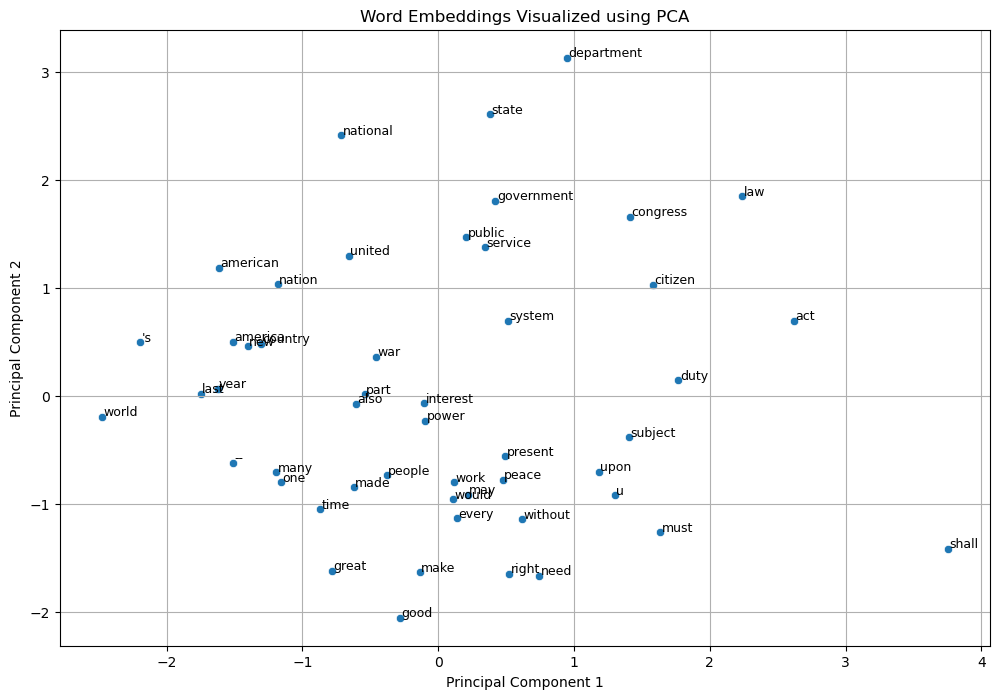

In [119]:
# Plotting the PCA-Reduced Vectors

# Create a DataFrame for plotting
df_pca = pd.DataFrame({
    'word': words,
    'x': word_vectors_pca[:, 0],
    'y': word_vectors_pca[:, 1]
})

# Plotting
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_pca, x='x', y='y')

# Annotate the points with words
for i in range(len(df_pca)):
    plt.text(df_pca['x'][i]+0.01, df_pca['y'][i]+0.01, df_pca['word'][i], fontsize=9)

plt.title('Word Embeddings Visualized using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()


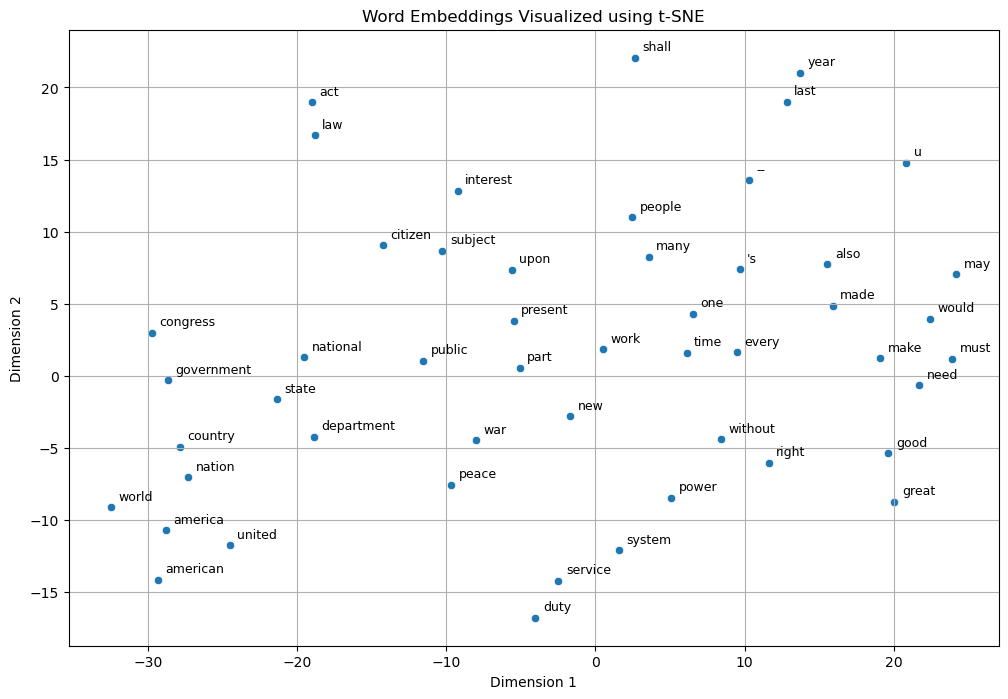

In [120]:
# Plotting the t-SNE-Reduced Vectors

# Create a DataFrame for plotting
df_tsne = pd.DataFrame({
    'word': words,
    'x': word_vectors_tsne[:, 0],
    'y': word_vectors_tsne[:, 1]
})

# Plotting
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_tsne, x='x', y='y')

# Annotate the points with words
for i in range(len(df_tsne)):
    plt.text(df_tsne['x'][i]+0.5, df_tsne['y'][i]+0.5, df_tsne['word'][i], fontsize=9)

plt.title('Word Embeddings Visualized using t-SNE')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid(True)
plt.show()


Explained variance ratio (PCA): [0.18825762 0.0963318  0.08708773]


/Users/mr.engelschion/anaconda3/envs/lda_env/lib/python3.10/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning:

'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.



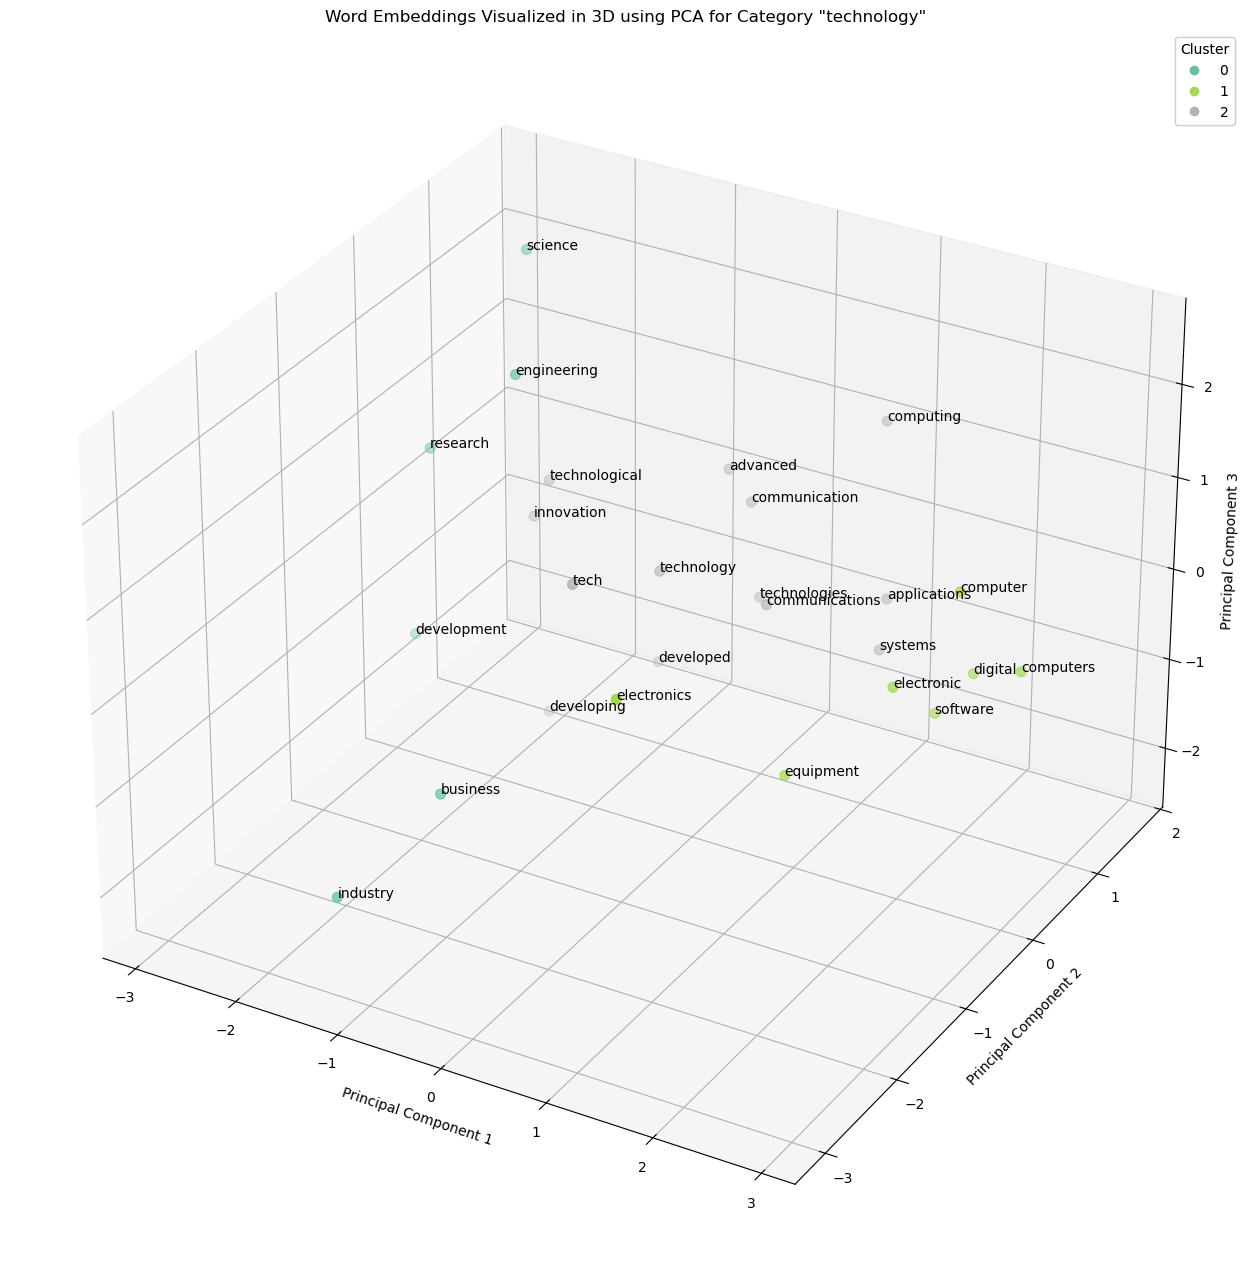

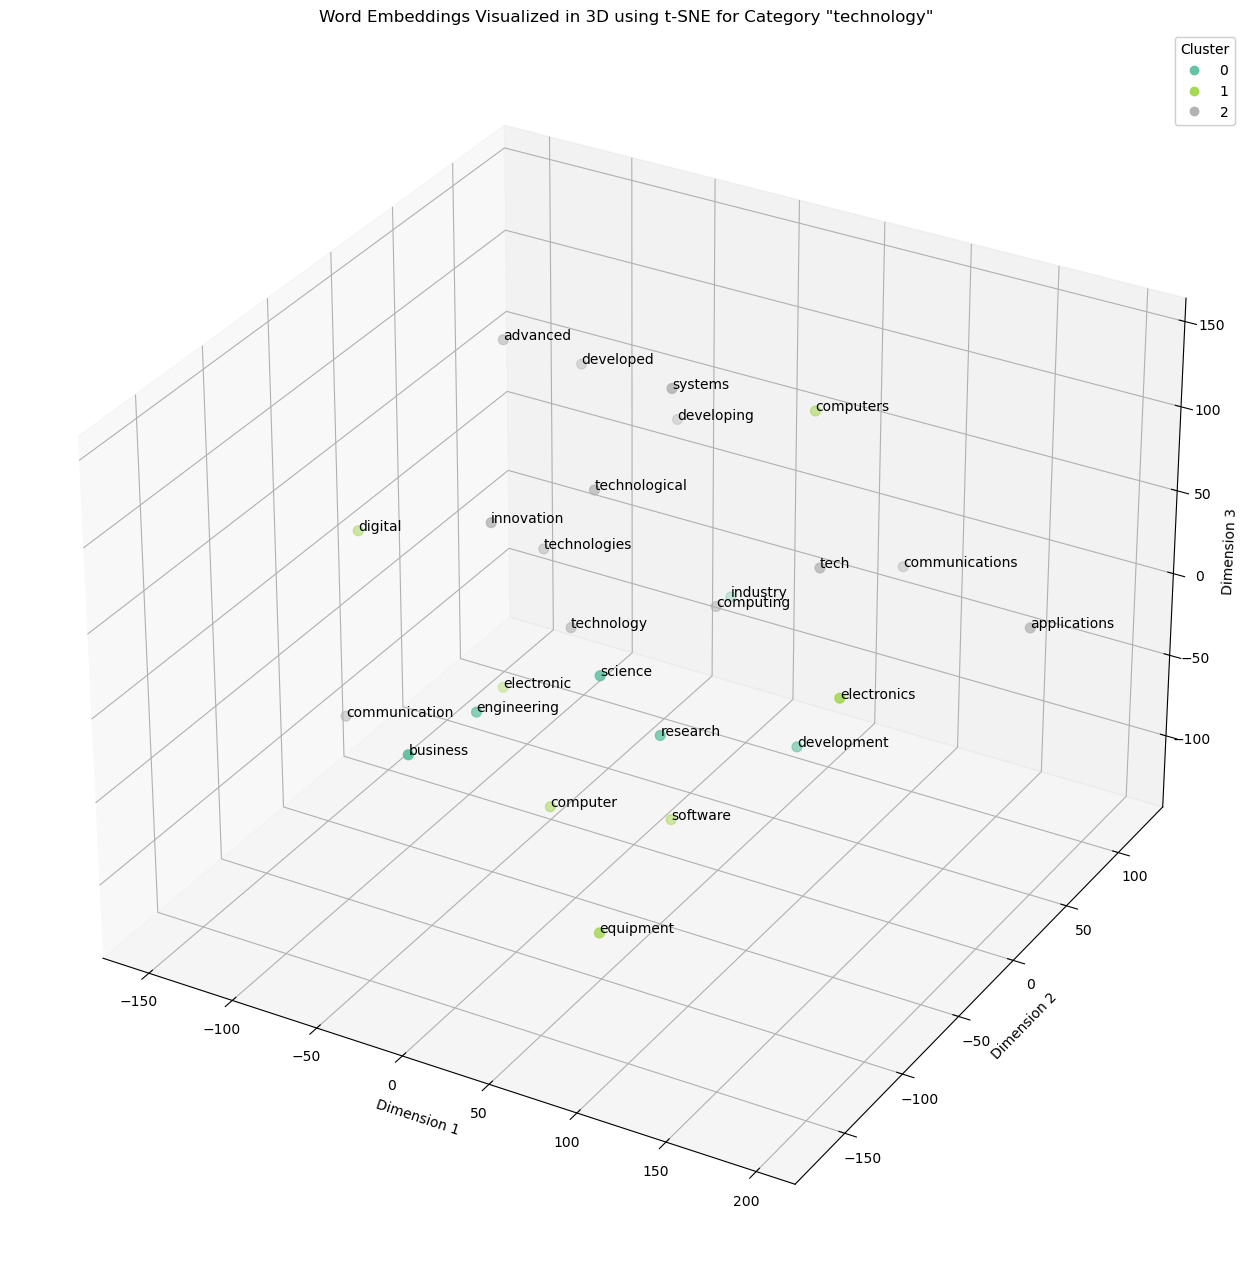

In [144]:
# Import necessary libraries
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
import pandas as pd
import gensim.downloader as api
import plotly.express as px

# Load pre-trained GloVe embeddings (vector size 100)
w2v_model = api.load('glove-wiki-gigaword-100')

# Function to get the most similar words
def get_similar_words(category_word, model, topn=25):
    try:
        similar_words = model.most_similar(category_word, topn=topn)
        words = [category_word]  # Include the category word itself
        words += [word for word, score in similar_words]
        return words
    except KeyError:
        print(f"'{category_word}' is not in the vocabulary.")
        return []

# Choose a category word
category_word = 'technology'

# Get the list of words
words = get_similar_words(category_word, w2v_model, topn=25)

# Get the vectors for the selected words
word_vectors = np.array([w2v_model[word] for word in words])

# Apply PCA to reduce dimensions to 3D
pca = PCA(n_components=3)
word_vectors_pca = pca.fit_transform(word_vectors)

print("Explained variance ratio (PCA):", pca.explained_variance_ratio_)

# Apply t-SNE to reduce dimensions to 3D
tsne = TSNE(n_components=3, perplexity=5, random_state=42, n_iter=1000)
word_vectors_tsne = tsne.fit_transform(word_vectors)

# Apply K-Means clustering on original word vectors
k = 3  # Number of clusters
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(word_vectors)
labels = kmeans.labels_

# Create DataFrames for PCA and t-SNE results
df_pca = pd.DataFrame({
    'word': words,
    'x': word_vectors_pca[:, 0],
    'y': word_vectors_pca[:, 1],
    'z': word_vectors_pca[:, 2],
    'cluster': labels
})

df_tsne = pd.DataFrame({
    'word': words,
    'x': word_vectors_tsne[:, 0],
    'y': word_vectors_tsne[:, 1],
    'z': word_vectors_tsne[:, 2],
    'cluster': labels
})

# Plotting PCA in 3D with Matplotlib
fig = plt.figure(figsize=(24, 16))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_pca['x'], df_pca['y'], df_pca['z'], c=df_pca['cluster'], cmap='Set2', s=50)

# Annotate the points with words
for i, word in enumerate(df_pca['word']):
    ax.text(df_pca['x'][i], df_pca['y'][i], df_pca['z'][i], word)

ax.set_title(f'Word Embeddings Visualized in 3D using PCA for Category "{category_word}"')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')

# Add legend
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend1)

plt.show()

# Plotting t-SNE in 3D with Matplotlib
fig = plt.figure(figsize=(24, 16))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_tsne['x'], df_tsne['y'], df_tsne['z'], c=df_tsne['cluster'], cmap='Set2', s=50)

# Annotate the points with words
for i, word in enumerate(df_tsne['word']):
    ax.text(df_tsne['x'][i], df_tsne['y'][i], df_tsne['z'][i], word)

ax.set_title(f'Word Embeddings Visualized in 3D using t-SNE for Category "{category_word}"')
ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_zlabel('Dimension 3')

# Add legend
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend1)

plt.show()

# Plotting PCA in 3D with Plotly
fig = px.scatter_3d(
    df_pca, x='x', y='y', z='z',
    color='cluster',
    text='word',
    title=f'Word Embeddings Visualized in 3D using PCA for Category "{category_word}"',
    width=1000, 
    height=800
)

# Update traces to adjust marker size and text font size
fig.update_traces(
    marker=dict(size=5),
    textfont_size=8,
    mode='markers+text',
    textposition='top center'
)

fig.show()

# Plotting t-SNE in 3D with Plotly
fig = px.scatter_3d(
    df_tsne, x='x', y='y', z='z',
    color='cluster',
    text='word',
    title=f'Word Embeddings Visualized in 3D using t-SNE for Category "{category_word}"',
    width=1000, 
    height=800
)

# Update traces to adjust marker size and text font size
fig.update_traces(
    marker=dict(size=5),
    textfont_size=8,
    mode='markers+text',
    textposition='top center'
)

fig.show()



### Part 4: Analyzing Changes in Word Meanings Over Time in Presidential Speeches

In this part, you'll investigate how the meanings of words have changed over time in presidential speeches. Building on the techniques learned in previous sections, you will focus on identifying and understanding shifts in language. No example code is provided for this section, so you are encouraged to approach the analysis either with your own code or in a more theoretical manner.

If you choose not to use code, describe in detail how you would theoretically conduct this analysis and interpret the findings. Also, point to potential difficulties or limitations you might encounter in such an analysis.

You can approach the below tasks with some freedom and for this exercise not all subtasks need to be completed or discussed in the final report. The goal is to think critically about how word embeddings can be used to analyze semantic change over time. Importantly, you should address the following questions in the final report:

As an advisor to a presidential campaign, how might you use your findings to inform your candidate’s language strategy?


#### I. Analyzing Change in Word Meanings Over Time:
1. **Comparing Word Meanings in Different Time Periods**  
   - Analyze how specific words may have changed in meaning between two distinct time periods (e.g., 1800 -- 1900 and 1900 -- 2000).
   - **Possible sub-tasks**:
     - Select a set of words that appear in both time periods. Think about words that may have shifted in relevance or context over time.
     - If using code, you could calculate word embeddings for each period and compare them to see how the “position” or “meaning” of the words has shifted. If not using code, explain how you might conceptually track these shifts, perhaps by examining the contexts in which these words appear.

2. **Measuring Semantic Change**  
   - Quantify or describe shifts in word meanings over time.
   - **Possible sub-tasks**:
     - If using code, you might measure semantic change by calculating the cosine similarity between word vectors for the same word across different periods. 
     - If you’re approaching this without coding, describe how you would interpret semantic shifts by comparing word associations, synonyms, or themes in each period.

### J. Visualizing Semantic Change  
- Illustrate the changes in word meanings across time.
  - **Possible sub-tasks**:
    - For those using code, you might create a plot of word vectors to show shifts in meaning visually. Consider how you might represent a word’s change in “position” on a timeline.
    - Without code, think about alternative ways to visualize this change. How would you present or describe a word’s evolving associations across different historical periods?

### K. Interpreting Semantic Shifts in Historical Context 
- Reflect on the broader implications of your findings.
  - **Possible sub-tasks**:
    - Can you find any words that have undergone significant shifts in meaning, potentially due to societal changes or historical events. Explain why these shifts are significant and how they reflect broader trends.
    - If you don’t have results, consider what types of shifts you would expect to find and what historical events or cultural changes might explain these.

In [153]:
# Import necessary libraries
import os
import pandas as pd

# Step 1: Load the Data
speech_directory = 'sotu/'
speech_files = [f for f in os.listdir(speech_directory) if f.endswith('.txt')]

# Extract speeches into a DataFrame
presidents, years, texts = [], [], []
for filename in speech_files:
    name_year = filename.replace('.txt', '')
    try:
        president, year = name_year.rsplit('_', 1)
    except ValueError:
        continue
    with open(os.path.join(speech_directory, filename), 'r', encoding='utf-8') as file:
        text = file.read()
    presidents.append(president)
    years.append(int(year))
    texts.append(text)

data = pd.DataFrame({'president': presidents, 'year': years, 'text': texts})

# Step 2: Filter and Output the Data for 1800-1900
filtered_data = data[(data['year'] >= 1800) & (data['year'] < 1900)]
for index, row in filtered_data.iterrows():
    print(f"Year: {row['year']}, President: {row['president']}")
    print(f"Speech Text: {row['text']}\n")
    print("-" * 50 + "\n")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


KeyboardInterrupt: 

In [155]:
# Import necessary libraries
import os
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from gensim.models import Word2Vec
from scipy.spatial.distance import cosine
from collections import Counter
import numpy as np

# Download NLTK data files (if not already downloaded)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Initialize lemmatizer and define stopwords
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Step 1: Load and Preprocess the Data
speech_directory = 'sotu/'  # Ensure this directory contains your speech text files
speech_files = [f for f in os.listdir(speech_directory) if f.endswith('.txt')]

# Extract speeches into a DataFrame
presidents, years, texts = [], [], []
for filename in speech_files:
    name_year = filename.replace('.txt', '')
    try:
        president, year = name_year.rsplit('_', 1)
    except ValueError:
        continue
    with open(os.path.join(speech_directory, filename), 'r', encoding='utf-8') as file:
        text = file.read()
    presidents.append(president)
    years.append(int(year))
    texts.append(text)
        
data = pd.DataFrame({'president': presidents, 'year': years, 'text': texts})

# Preprocessing function with stopword removal and lemmatization
def preprocess_text(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word.strip(string.punctuation) for word in tokens if word.isalpha()]
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return tokens

# Apply preprocessing to speeches
data['tokens'] = data['text'].apply(preprocess_text)

# Step 2: Split Data into Time Periods
# Define time periods
time_periods = {
    '1800-1900': data[(data['year'] >= 1800) & (data['year'] < 1900)],
    '1900-2000': data[(data['year'] >= 1900) & (data['year'] < 2000)]
}

# Step 3: Train Word2Vec Models for Each Time Period
# Set random seed for reproducibility
np.random.seed(42)

models = {}
for period, subset in time_periods.items():
    # Flatten the list of tokens
    sentences = subset['tokens'].tolist()
    models[period] = Word2Vec(
        sentences=sentences,
        vector_size=100,
        window=5,
        min_count=5,  # Increase min_count to focus on more common words
        workers=4,
        sg=1,
        epochs=10,
        seed=42
    )

# Step 4: Identify Common Words
# Get vocabulary for each period
vocab_1800_1900 = set(models['1800-1900'].wv.index_to_key)
vocab_1900_2000 = set(models['1900-2000'].wv.index_to_key)

# Find common words
common_words = vocab_1800_1900 & vocab_1900_2000

# Remove stopwords from common words
common_words = [word for word in common_words if word not in stop_words]

# Step 5: Calculate Cosine Similarities for All Common Words
cosine_similarities = {}
for word in common_words:
    vector1 = models['1800-1900'].wv[word]
    vector2 = models['1900-2000'].wv[word]
    similarity = 1 - cosine(vector1, vector2)
    cosine_similarities[word] = similarity

# Step 6: Identify Words with Significant Semantic Shifts
# Sort words by similarity (ascending order)
sorted_words = sorted(cosine_similarities.items(), key=lambda item: item[1])

# Get top 50 words with the lowest similarity (most significant shifts)
top_shifted_words = sorted_words[:50]

# Display the results
print("Top 50 words with most significant semantic shifts:")
for word, similarity in top_shifted_words:
    print(f"Word: {word}, Cosine Similarity: {similarity:.4f}")

# Step 7: Analyze and Interpret Results
# For the top shifted words, display their most similar words in each period
def get_top_similar_words(model, word, top_n=5):
    return model.wv.most_similar(word, topn=top_n)

print("\nContextual Neighbors for Top Shifted Words:")
for word, similarity in top_shifted_words:
    print(f"\nWord: '{word}', Cosine Similarity: {similarity:.4f}")
    for period, model in models.items():
        if word in model.wv:
            similar_words = get_top_similar_words(model, word)
            similar_words_str = ', '.join([w for w, _ in similar_words])
            print(f"{period}: {similar_words_str}")
        else:
            print(f"'{word}' not found in the model for period {period}.")


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Top 50 words with most significant semantic shifts:
Word: political, Cosine Similarity: -0.1398
Word: company, Cosine Similarity: -0.1159
Word: still, Cosine Similarity: -0.0925
Word: difference, Cosine Similarity: -0.0810
Word: face, Cosine Similarity: -0.0609
Word: less, Cosine Similarity: -0.0453
Word: different, Cosine Similarity: -0.0432
Word: history, Cosine Similarity: -0.0399
Word: capital, Cosine Similarity: -0.0268
Word: courage, Cosine Similarity: -0.0206
Word: existed, Cosine Similarity: -0.0105
Word: inflation, Cosine Similarity: -0.0090
Word: reason, Cosine Similarity: -0.0087
Word: ago, Cosine Similarity: -0.0024
Word: price, Cosine Similarity: -0.0021
Word: bill, Cosine Similarity: -0.0004
Word: fortune, Cosine Similarity: -0.0004
Word: stop, Cosine Similarity: 0.0007
Word: crime, Cosine Similarity: 0.0016
Word: relationship, Cosine Similarity: 0.0026
Word: man, Cosine Similarity: 0.0033
Word: organized, Cosine Similarity: 0.0038
Word: security, Cosine Similarity: 0.004

In [158]:
# Import necessary libraries
import os
import pandas as pd
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from gensim.models import Word2Vec
from scipy.spatial.distance import cosine
import numpy as np
from sklearn.decomposition import PCA

# Import Plotly libraries
import plotly.express as px
import plotly.graph_objects as go

# Download NLTK data files (if not already downloaded)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

# Initialize lemmatizer and define stopwords
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Step 1: Load and Preprocess the Data
speech_directory = 'sotu/'  # Ensure this directory contains your speech text files
speech_files = [f for f in os.listdir(speech_directory) if f.endswith('.txt')]

# Extract speeches into a DataFrame
presidents, years, texts = [], [], []
for filename in speech_files:
    name_year = filename.replace('.txt', '')
    try:
        president, year = name_year.rsplit('_', 1)
    except ValueError:
        continue
    with open(os.path.join(speech_directory, filename), 'r', encoding='utf-8') as file:
        text = file.read()
    presidents.append(president)
    years.append(int(year))
    texts.append(text)
        
data = pd.DataFrame({'president': presidents, 'year': years, 'text': texts})

# Preprocessing function with stopword removal and lemmatization
def preprocess_text(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word.strip(string.punctuation) for word in tokens if word.isalpha()]
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return tokens

# Apply preprocessing to speeches
data['tokens'] = data['text'].apply(preprocess_text)

# Step 2: Split Data into Time Periods
# Define time periods
time_periods = {
    '1800-1900': data[(data['year'] >= 1800) & (data['year'] < 1900)],
    '1900-2000': data[(data['year'] >= 1900) & (data['year'] < 2000)]
}

# Step 3: Train Word2Vec Models for Each Time Period
# Set random seed for reproducibility
np.random.seed(42)

models = {}
for period, subset in time_periods.items():
    # Flatten the list of tokens
    sentences = subset['tokens'].tolist()
    models[period] = Word2Vec(
        sentences=sentences,
        vector_size=100,
        window=5,
        min_count=5,  # Increase min_count to focus on more common words
        workers=4,
        sg=1,
        epochs=10,
        seed=42
    )

# Step 4: Identify Common Words
# Get vocabulary for each period
vocab_1800_1900 = set(models['1800-1900'].wv.index_to_key)
vocab_1900_2000 = set(models['1900-2000'].wv.index_to_key)

# Find common words
common_words = vocab_1800_1900 & vocab_1900_2000

# Remove stopwords from common words
common_words = [word for word in common_words if word not in stop_words]

# Step 5: Calculate Cosine Similarities for All Common Words
cosine_similarities = {}
for word in common_words:
    vector1 = models['1800-1900'].wv[word]
    vector2 = models['1900-2000'].wv[word]
    similarity = 1 - cosine(vector1, vector2)
    cosine_similarities[word] = similarity

# Step 6: Identify Words with Significant Semantic Shifts
# Sort words by similarity (ascending order)
sorted_words = sorted(cosine_similarities.items(), key=lambda item: item[1])

# Get top 50 words with the lowest similarity (most significant shifts)
top_shifted_words = sorted_words[:50]

# Display the results
print("Top 50 words with most significant semantic shifts:")
for word, similarity in top_shifted_words:
    print(f"Word: {word}, Cosine Similarity: {similarity:.4f}")

# Step 7: Analyze and Interpret Results
# For the top shifted words, display their most similar words in each period
def get_top_similar_words(model, word, top_n=5):
    return model.wv.most_similar(word, topn=top_n)

print("\nContextual Neighbors for Top Shifted Words:")
for word, similarity in top_shifted_words:
    print(f"\nWord: '{word}', Cosine Similarity: {similarity:.4f}")
    for period, model in models.items():
        if word in model.wv:
            similar_words = get_top_similar_words(model, word)
            similar_words_str = ', '.join([w for w, _ in similar_words])
            print(f"{period}: {similar_words_str}")
        else:
            print(f"'{word}' not found in the model for period {period}.")

# Step 8: Visualize Semantic Change using Plotly

# Select words for visualization
selected_words = ['political', 'company', 'inflation', 'gay']

# For each selected word, create a visualization
for target_word in selected_words:
    vectors = []
    labels = []
    periods = []
    
    periods_present = []
    for period in ['1800-1900', '1900-2000']:
        model = models[period]
        if target_word in model.wv:
            periods_present.append(period)
            # Get the target word vector
            vectors.append(model.wv[target_word])
            labels.append(target_word)
            periods.append(period)
            # Get vectors for top similar words
            similar_words = get_top_similar_words(model, target_word, top_n=5)
            for word, _ in similar_words:
                vectors.append(model.wv[word])
                labels.append(word)
                periods.append(period)
        else:
            print(f"'{target_word}' not found in the model for period {period}.")

    # Check if we have enough vectors to perform PCA
    if len(vectors) < 2:
        print(f"Not enough data to visualize the word '{target_word}'. Skipping to next word.\n")
        continue

    # Convert vectors to numpy array
    vectors = np.array(vectors)

    # Dimensionality reduction
    pca = PCA(n_components=2)
    try:
        vectors_2d = pca.fit_transform(vectors)
    except ValueError as e:
        print(f"Error performing PCA on word '{target_word}': {e}")
        continue

    # Create DataFrame for plotting
    df_plot = pd.DataFrame({
        'x': vectors_2d[:, 0],
        'y': vectors_2d[:, 1],
        'label': labels,
        'period': periods
    })

    # Assign colors based on period
    color_map = {'1800-1900': 'red', '1900-2000': 'blue'}
    df_plot['color'] = df_plot['period'].map(color_map)

    # Create Plotly figure
    fig = go.Figure()

    # Add scatter traces for each period
    for period in df_plot['period'].unique():
        df_period = df_plot[df_plot['period'] == period]
        fig.add_trace(go.Scatter(
            x=df_period['x'],
            y=df_period['y'],
            mode='markers+text',
            text=df_period['label'],
            textposition='top center',
            marker=dict(size=10, color=color_map[period]),
            name=period
        ))

    # Update layout
    fig.update_layout(
        title=f"Semantic Shift Visualization for '{target_word}'",
        xaxis_title='Principal Component 1',
        yaxis_title='Principal Component 2',
        legend_title='Time Period',
        legend=dict(
            x=0.85,
            y=0.95
        )
    )

    # Show the figure
    fig.show()


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/mr.engelschion/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Top 50 words with most significant semantic shifts:
Word: labor, Cosine Similarity: -0.1200
Word: social, Cosine Similarity: -0.1041
Word: already, Cosine Similarity: -0.0710
Word: improvement, Cosine Similarity: -0.0681
Word: political, Cosine Similarity: -0.0678
Word: inflation, Cosine Similarity: -0.0596
Word: naval, Cosine Similarity: -0.0538
Word: law, Cosine Similarity: -0.0467
Word: history, Cosine Similarity: -0.0367
Word: still, Cosine Similarity: -0.0319
Word: energy, Cosine Similarity: -0.0304
Word: achievement, Cosine Similarity: -0.0294
Word: bill, Cosine Similarity: -0.0286
Word: source, Cosine Similarity: -0.0261
Word: real, Cosine Similarity: -0.0248
Word: company, Cosine Similarity: -0.0238
Word: past, Cosine Similarity: -0.0224
Word: experience, Cosine Similarity: -0.0212
Word: force, Cosine Similarity: -0.0211
Word: wage, Cosine Similarity: -0.0185
Word: case, Cosine Similarity: -0.0146
Word: face, Cosine Similarity: -0.0136
Word: security, Cosine Similarity: -0.0135

'gay' not found in the model for period 1800-1900.
'gay' not found in the model for period 1900-2000.
Not enough data to visualize the word 'gay'. Skipping to next word.

